# 04 · Error analysis

Where the final model succeeds and fails. **Every metric in this notebook is for
RoBERTa-base (`checkpoints/model_best.pt`) on the test split** (6,395 reviews). Predictions are computed once
from `checkpoints/model_best.pt` and cached in `runs/predictions_test_model_best.csv`
(about 1 minute on the GPU, about 10 on a CPU); later runs read the cache.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ["TQDM_DISABLE"] = "1"  # no progress bars in the rendered notebook
warnings.filterwarnings("ignore", category=UserWarning)

# Notebooks run with notebooks/ as the working directory; make `src` importable.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import plots
from src.config import LABELS, RUNS_DIR

plots.apply_theme()
pd.set_option("display.precision", 4)

import torch
from sklearn.metrics import f1_score

In [2]:
from src.data import load_split_frames
from src.config import BEST_CHECKPOINT

CACHE = RUNS_DIR / "predictions_test_model_best.csv"
test = load_split_frames()["test"]

if CACHE.exists():
    predictions = pd.read_csv(CACHE, index_col=0)
else:
    from src.config import get_device
    from src.data import build_loaders
    from src.evaluate import predict
    from src.model import load_checkpoint

    device = get_device()
    model, tokenizer, config, _ = load_checkpoint(BEST_CHECKPOINT, device)
    config.limit = 0
    loaders, _ = build_loaders(tokenizer, config, splits=("test",))
    probabilities, y_true, _ = predict(model, loaders["test"], device, config.bf16)
    predictions = pd.DataFrame(probabilities, columns=[f"p_{label}" for label in LABELS],
                               index=test.index)
    predictions["true"] = [LABELS[i] for i in y_true]
    predictions["pred"] = [LABELS[i] for i in probabilities.argmax(axis=1)]
    predictions.to_csv(CACHE)

silver = pd.read_parquet(ROOT / "data" / "silver" / "reviews.parquet")
df = predictions.join(silver[["Review_Text", "Branch", "Rating"]])
df["correct"] = df.true == df.pred
df["confidence"] = df[[f"p_{label}" for label in LABELS]].max(axis=1)
df["n_words"] = df.Review_Text.str.count(r"\S+")
assert len(df) == 6395 and (df.true == test["sentiment"].astype(str)).all()
print(f"RoBERTa-base · test accuracy {df.correct.mean():.4f} · macro-F1 "
      f"{f1_score(df.true, df.pred, average='macro'):.4f}")

RoBERTa-base · test accuracy 0.8460 · macro-F1 0.7130


## 1. Errors by star rating — RoBERTa-base (test)

The target merges 1–2 stars (negative) and 4–5 stars (positive); the rating itself shows
where inside each class the errors concentrate.

In [3]:
by_rating = df.groupby("Rating").agg(reviews=("correct", "size"), accuracy=("correct", "mean"),
                                     predicted_neutral=("pred", lambda p: (p == "neutral").mean())).rename_axis(columns="RoBERTa-base · test")
by_rating

RoBERTa-base · test,reviews,accuracy,predicted_neutral
Rating,,,
1,228,0.8772,0.1184
2,316,0.6171,0.3544
3,766,0.6475,0.6475
4,1646,0.7205,0.2710
5,3439,0.9692,0.0276


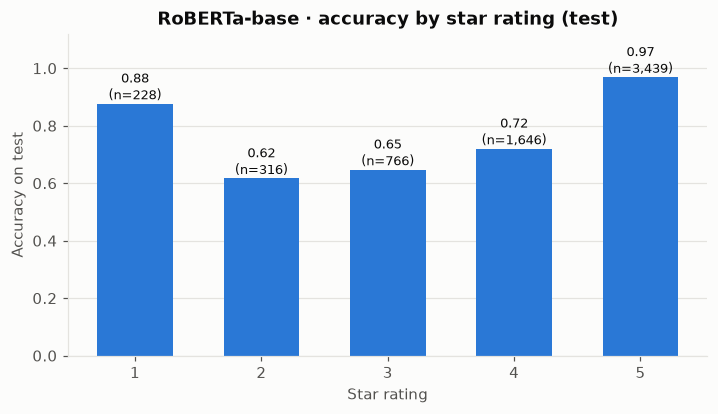

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
bars = ax.bar(by_rating.index.astype(str), by_rating.accuracy, color=plots.SERIES[0], width=0.6)
for bar, (stars, row) in zip(bars, by_rating.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, row.accuracy + 0.015,
            f"{row.accuracy:.2f}\n(n={int(row.reviews):,})", ha="center", fontsize=8.5)
ax.set_ylim(0, 1.12)
ax.set_xlabel("Star rating")
ax.set_ylabel("Accuracy on test")
ax.set_title("RoBERTa-base · accuracy by star rating (test)")
ax.grid(axis="x", visible=False)
plots.save(fig, "w2_accuracy_by_rating")
plt.show()

## 2. Errors by review length — RoBERTa-base (test)

Reviews longer than ~190 words exceed the 256-token window and are truncated head+tail.

In [5]:
bins = [0, 50, 100, 190, 400, np.inf]
names = ["≤50", "51–100", "101–190", "191–400 (truncated)", ">400 (truncated)"]
df["length"] = pd.cut(df.n_words, bins=bins, labels=names)
by_length = df.groupby("length", observed=True).apply(
    lambda g: pd.Series({"reviews": len(g), "accuracy": g.correct.mean(),
                         "macro_f1": f1_score(g.true, g.pred, average="macro")}),
    include_groups=False).astype({"reviews": int}).rename_axis(columns="RoBERTa-base · test")
by_length

RoBERTa-base · test,reviews,accuracy,macro_f1
length,,,
≤50,1983,0.8896,0.7190
51–100,1769,0.8525,0.7085
101–190,1414,0.8253,0.7072
191–400 (truncated),935,0.7904,0.6993
>400 (truncated),294,0.7891,0.7231


## 3. Errors by park — RoBERTa-base (test)

In [6]:
by_park = df.groupby("Branch").apply(
    lambda g: pd.Series({"reviews": len(g), "accuracy": g.correct.mean(),
                         "macro_f1": f1_score(g.true, g.pred, average="macro"),
                         "share_negative": (g.true == "negative").mean()}),
    include_groups=False).astype({"reviews": int}).sort_values("macro_f1").rename_axis(columns="RoBERTa-base · test")
by_park

RoBERTa-base · test,reviews,accuracy,macro_f1,share_negative
Branch,,,,
Disneyland_HongKong,1396,0.8159,0.6820,0.0487
Disneyland_California,2890,0.8720,0.7059,0.0702
Disneyland_Paris,2109,0.8303,0.7275,0.1294


## 4. Confidence — is RoBERTa-base sure when it is right? (test)

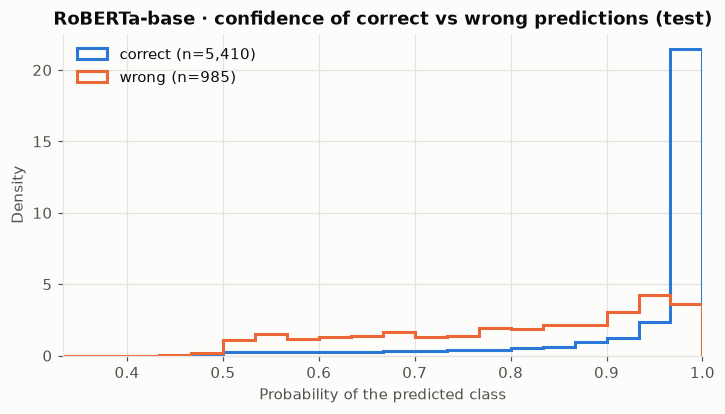

RoBERTa-base · test · confidence of the predicted class
           mean     50%
correct                
False    0.8040  0.8375
True     0.9481  0.9948


In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
edges = np.linspace(1 / 3, 1, 21)
ax.hist(df.loc[df.correct, "confidence"], bins=edges, histtype="step", lw=2,
        color=plots.SERIES[0], label=f"correct (n={df.correct.sum():,})", density=True)
ax.hist(df.loc[~df.correct, "confidence"], bins=edges, histtype="step", lw=2,
        color=plots.SERIES[1], label=f"wrong (n={(~df.correct).sum():,})", density=True)
ax.set_xlim(1 / 3, 1)
ax.set_xlabel("Probability of the predicted class")
ax.set_ylabel("Density")
ax.set_title("RoBERTa-base · confidence of correct vs wrong predictions (test)")
ax.legend(loc="upper left")
plots.save(fig, "w2_confidence")
plt.show()
print("RoBERTa-base · test · confidence of the predicted class")
print(df.groupby("correct").confidence.describe()[["mean", "50%"]])

## 5. Examples of errors — RoBERTa-base (test)

The most confident mistakes of each kind. Texts are cut to 300 characters.

In [8]:
pd.set_option("display.max_colwidth", 300)

def worst(true, pred, n=3):
    rows = df[(df.true == true) & (df.pred == pred)].sort_values("confidence", ascending=False)
    return rows.head(n).assign(text=lambda f: f.Review_Text.str[:300])[
        ["Rating", "Branch", "confidence", "text"]]

for true, pred in (("positive", "neutral"), ("neutral", "negative"),
                   ("negative", "neutral"), ("positive", "negative")):
    print(f"\n=== true {true} → predicted {pred}: "
          f"{((df.true == true) & (df.pred == pred)).sum()} reviews")
    display(worst(true, pred))


=== true positive → predicted neutral: 541 reviews


,Rating,Branch,confidence,text
22714,4,Disneyland_California,0.9902,"I am from Melbourne and have only been to the themeparks in Queensland so I was expecting a big step up.. which I didn't really get.Certainly the attention to detail was much more impressive and the experience of the ride was where they have heavily invested, but for the waiting lines the rides ..."
17761,4,Disneyland_California,0.9886,"Having waiting all my life to go to Disneyland I was a little underwhelmed. I had read reviews that had mentioned how congested it was but I was not really prepared for the amount of people and the amount of time queuing. Also on top of an expensive day out, everything you brought there was very..."
12629,4,Disneyland_California,0.9881,Three year old twins loved it but I was disappointed. Used to Magic Kingdom at Disneyworld. No princesses and not quite as clean.



=== true neutral → predicted negative: 168 reviews


,Rating,Branch,confidence,text
11010,3,Disneyland_California,0.9987,"My one year passport expired and I cannot tell you how much I hate Disneyland after this experience.So many people no matter what day you go, food is very expensive, and no new rides in years. They are putting all their money into star wars for next summer. They even pulled out the professional ..."
20734,3,Disneyland_California,0.9982,"Overpriced, too busy, even on a weekday. Spent all day and only got to ride two or three rides. Definitely not worth the price."
28502,3,Disneyland_California,0.9981,"I live in Southern California and bought a premium annual pass to go any day of the year. My pass expired in August and I am not renewing it. Not only is it very expensive, but it's also extremely crowded even in this so called economic recession. Don't even try to go on a weekend or holiday, ..."



=== true negative → predicted neutral: 139 reviews


,Rating,Branch,confidence,text
10724,2,Disneyland_California,0.9832,"We have been to Disney world several times and have also been on several Disney cruise so when in Anaheim we had to go here. I know it s the original and was pumped after reading reviews. I found it small, old and lacking the Disney magic we experienced with other Disney vacations. I was..."
35742,2,Disneyland_Paris,0.9827,This is our third visit in over fifteen years second in two years .I felt the attraction is getting passed its sell by date and needs to have some money spent on it to bring the magical feeling back .At least four rides were closed for refurbishment we felt a bit odd to do that is the main Schoo...
5694,2,Disneyland_HongKong,0.9796,"After 24 days of travel in China, I decided to satisfy my daughter's insistent requests to visit Hong Kong Disneyland. Well, that was a disappointment: the park is very small, expecially when compared to the ones in the US, and, considering the number of visitors, the time spent in the heat queu..."



=== true positive → predicted negative: 25 reviews


,Rating,Branch,confidence,text
407,5,Disneyland_HongKong,0.9930,"A pain. Over expensive. Over cheesy, touristic rip off in one centre. Felt like my entire life s savings were being squeezed out of me. Ok for the kids but even they got bored of stuff too quickly. Needs rethinking"
7731,4,Disneyland_HongKong,0.9921,"this place is invaded by China men. Noisy, rough, littering and smoking. What do you feel if you see a group of chinese sharing an orange in the main street?"
34115,4,Disneyland_Paris,0.9916,"When you consider the fact that this resort is losing money and that the week we visited was a local holiday week, then it was disappointing that many rides and attractions were not open! Both the train rides were either limited (train not working) or kept breaking down! French organisation and ..."


## Findings

All figures below: RoBERTa-base, test split.

- **Errors live at the class boundaries of the rating scale.** 5-star reviews are 97 %
  correct and 1-star 88 %, but 2-star (62 %), 3-star (65 %) and 4-star (72 %) are hard:
  35 % of 2-star and 27 % of 4-star reviews are predicted neutral. The label is a binning
  of an ordinal scale, and the model struggles exactly where the bins meet.
- **Truncation is not the problem.** Accuracy falls with length (0.89 for ≤50 words to
  0.79 for long reviews), but macro-F1 stays flat (0.70–0.72), and the longest, truncated
  reviews (>400 words) score the *highest* macro-F1 (0.723). Long reviews are simply more
  often mixed; head+tail truncation keeps the verdict.
- **Hong Kong is the hardest park** (macro-F1 0.682, with only 4.9 % negative reviews);
  Paris, with the most negatives (12.9 %), is the easiest (0.728).
- **The model is overconfident when wrong.** Wrong predictions still have a median
  confidence of 0.84 (0.995 when right). This matches the rising validation loss in
  notebook 02; temperature scaling on validation would calibrate the probabilities
  without changing any prediction.
- **Part of the error is label noise.** Some of the most confident "mistakes" are reviews
  whose text contradicts their stars, e.g. a **5-star** review that reads *"A pain. Over
  expensive. Over cheesy, touristic rip off"*, predicted negative, or a **3-star** review
  saying *"I cannot tell you how much I hate Disneyland"*. The model follows the text;
  the rating does not always do the same. This sets a ceiling on attainable accuracy.